# Demo: ViT chơi Ms. Pacman

Model: `vit_dp2_sp0.05_plus5M_from_A_s0`, ViT nhỏ (~612 nghìn tham số), ảnh xám 4 khung 84x84. Đây là run ViT tốt nhất trong các run đã train (chuỗi 4 giai đoạn, tổng ~13M bước; xem `compare_best_models.ipynb`).

Notebook này có 3 cách xem:

1. **Quay ván thành GIF/MP4** (mục 4): chạy offscreen, hiển thị ngay trong notebook, kèm thanh xác suất 9 hành động. Không cần cửa sổ game. Phù hợp để demo hoặc chèn vào slide.
2. **Cửa sổ trực tiếp có bảng xác suất** (mục 5): cần màn hình và OpenCV, nhấn `q` để thoát.
3. **Quét seed để tìm ván hay** (mục 3, tùy chọn).

Ghi chú về chất lượng, từ lần thử của tôi trên 20 ván (seed 0–19): chế độ **lấy mẫu từ policy** cho trung bình ~1250 điểm (cao nhất 3930, seed 9); chế độ greedy kém hơn (~1000–1090). Điểm mỗi ván dao động rất mạnh (một ván có thể 600, ván khác 3900), nên một ván demo đơn lẻ **không đại diện** cho mức trung bình; nên nói rõ điều này khi trình bày. Để so sánh, người chơi thử nghiệm chuyên nghiệp trong bài báo DQN (Mnih và cộng sự, 2015) đạt khoảng 15 700 điểm.

## 0. Cấu hình

In [9]:
import random, time
from pathlib import Path
import numpy as np
import torch
from PIL import Image, ImageDraw
from IPython.display import Image as IPImage, display

from pacman_rl import get_device
from pacman_rl.runs import load_run
from pacman_rl.envs import make_env

RUN_DIR = "runs"                              # chạy notebook từ thư mục notebooks/
MODEL_NAME = "vit_dp2_sp0.05_plus5M_from_A_s0"
DEMO_SEED = 9                                 # seed của ván demo (trong thử nghiệm: 3930 điểm; seed 2 ra 1800). Đổi nếu muốn ván khác
GREEDY, EPS = False, 0.0                      # False = lấy mẫu từ policy (tốt nhất trong thử nghiệm)
SCAN = False                                  # True: quét N_SCAN seed (mất ~10 giây/ván) rồi chọn seed điểm cao nhất
N_SCAN = 20
OUT_DIR = Path(RUN_DIR) / "demo"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Nạp model

In [2]:
device = get_device()
model = load_run(RUN_DIR, MODEL_NAME, "ppo", device).model.to(device).eval()
print(f"device: {device} | {MODEL_NAME} | {sum(p.numel() for p in model.parameters()):,} tham số | "
      f"đầu vào {'RGB' if model.in_channels == 12 else 'xám'} ({model.in_channels} kênh)")

device: cuda | vit_dp2_sp0.05_plus5M_from_A_s0 | 611,850 tham số | đầu vào xám (4 kênh)


## 2. Hàm chơi một ván

`play(seed, ...)` chơi đủ một ván 3 mạng với seed cố định (môi trường tất định: `repeat_action_probability = 0`; việc lấy mẫu hành động cũng được gieo seed), nên cùng seed cho cùng điểm. Hai mức chạy lại có thể lệch nhẹ nếu GPU tính khác nhau; mục 4 in cả hai điểm để bạn thấy.

In [3]:
def _frame(env, probs, action, names, score, step, scale):
    game = Image.fromarray(env.render()).resize((160 * scale, 210 * scale), Image.NEAREST)
    W, H = game.size
    canvas = Image.new("RGB", (W + 240, H), (15, 15, 20))
    canvas.paste(game, (0, 0))
    d = ImageDraw.Draw(canvas)
    d.text((W + 10, 8), f"score {score:.0f}   step {step}", fill=(255, 220, 80))
    for i, (nm, p) in enumerate(zip(names, probs)):
        y = 34 + i * 26
        color = (60, 200, 90) if i == action else (130, 130, 140)
        d.text((W + 10, y), nm, fill=(235, 235, 235))
        d.rectangle([W + 90, y + 2, W + 90 + int(p * 110), y + 12], fill=color)
        d.text((W + 90 + int(p * 110) + 4, y), f"{p:.2f}", fill=(235, 235, 235))
    return canvas


def play(seed, greedy=GREEDY, eps=EPS, record=False, every=2, scale=2, max_steps=4500):
    """Chơi 1 ván. record=True: trả về (điểm, số bước, danh sách khung PIL kèm bảng xác suất)."""
    random.seed(seed); torch.manual_seed(seed)
    env = make_env(render_mode="rgb_array" if record else None, rgb_scale=model.in_channels == 12)
    names = env.unwrapped.get_action_meanings()
    obs, _ = env.reset(seed=seed)
    score, steps, done, frames = 0.0, 0, False, []
    try:
        while not done and steps < max_steps:
            with torch.no_grad():
                dist, _ = model(torch.as_tensor(np.asarray(obs), device=device).unsqueeze(0))
            p = dist.probs[0].cpu().numpy()
            a = int(p.argmax()) if greedy else int(dist.sample().item())
            if eps and random.random() < eps:
                a = random.randrange(len(p))
            if record and steps % every == 0:
                frames.append(_frame(env, p, a, names, score, steps, scale))
            obs, r, te, tr, _ = env.step(a)
            score += r; steps += 1; done = te or tr
    finally:
        env.close()
    return score, steps, frames

## 3. (Tùy chọn) Quét seed để chọn ván demo

Đặt `SCAN = True` ở mục 0. Mỗi ván mất khoảng 10 giây (20 ván ≈ 3–4 phút). Seed điểm cao nhất sẽ thành `DEMO_SEED`. Lưu ý: chọn ván tốt nhất trong nhiều ván là **chọn lọc có chủ đích** để trình diễn, không phải phép đo hiệu năng; bảng thống kê bên dưới mới là mức trung bình thực.

In [4]:
if SCAN:
    import pandas as pd
    res = []
    for s in range(N_SCAN):
        t = time.time()
        sc, st, _ = play(s)
        res.append({"seed": s, "điểm": sc, "bước": st})
        print(f"seed {s:3d}: {sc:6.0f} điểm, {st} bước ({time.time() - t:.0f}s)", flush=True)
    df = pd.DataFrame(res)
    print(f"\n{N_SCAN} ván: TB {df['điểm'].mean():.0f} | trung vị {df['điểm'].median():.0f} | "
          f"tối đa {df['điểm'].max():.0f} | tối thiểu {df['điểm'].min():.0f}")
    DEMO_SEED = int(df.loc[df["điểm"].idxmax(), "seed"])
    print("DEMO_SEED =", DEMO_SEED)
    display(df.sort_values("điểm", ascending=False).head(5).reset_index(drop=True))
else:
    print(f"SCAN = False: dùng DEMO_SEED = {DEMO_SEED}")

SCAN = False: dùng DEMO_SEED = 9


## 4. Quay ván demo (GIF hiển thị trong notebook, MP4 lưu vào `runs/demo/`)

Khung bên trái là game, bên phải là xác suất 9 hành động (thanh xanh = hành động được chọn). Chỉ ghi 1 trong mỗi `every` bước để file gọn.

c:\Users\LENOVO\miniconda3\envs\rel_pacman\lib\site-packages\torch\nn\modules\transformer.py:720: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:455.)
  return torch._transformer_encoder_layer_fwd(


seed 9: 3930 điểm, 868 bước, 434 khung (6s)
đã lưu runs\demo\vit_seed9_3930pts.gif (1.4 MB)
đã lưu runs\demo\vit_seed9_3930pts.mp4 (2.8 MB)


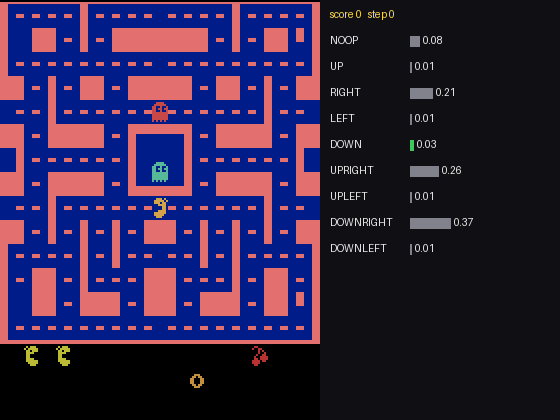

In [5]:
EVERY, SCALE = 2, 2
t = time.time()
score, steps, frames = play(DEMO_SEED, record=True, every=EVERY, scale=SCALE)
print(f"seed {DEMO_SEED}: {score:.0f} điểm, {steps} bước, {len(frames)} khung ({time.time() - t:.0f}s)")

gif = OUT_DIR / f"vit_seed{DEMO_SEED}_{int(score)}pts.gif"
frames[0].save(gif, save_all=True, append_images=frames[1:], duration=int(1000 / 60 * 4 * EVERY), loop=0, optimize=True)
print(f"đã lưu {gif} ({gif.stat().st_size / 1e6:.1f} MB)")

try:                                                    # MP4 nếu có OpenCV (nhẹ hơn GIF nhiều)
    import cv2
    mp4 = gif.with_suffix(".mp4")
    w, h = frames[0].size
    vw = cv2.VideoWriter(str(mp4), cv2.VideoWriter_fourcc(*"mp4v"), 60 / (4 * EVERY), (w, h))
    for f in frames:
        vw.write(cv2.cvtColor(np.asarray(f), cv2.COLOR_RGB2BGR))
    vw.release()
    print(f"đã lưu {mp4} ({mp4.stat().st_size / 1e6:.1f} MB)")
except Exception as e:
    print("bỏ qua MP4:", type(e).__name__, e)

display(IPImage(filename=str(gif)))

## 5. Xem trực tiếp trong cửa sổ có bảng xác suất (cần màn hình + OpenCV)

Phím `q` để thoát. Chạy ván khác bằng cách đổi `seed` (hoặc `None` để ngẫu nhiên). Với `greedy=False` kết quả mỗi lần chạy khác nhau.

In [12]:
from pacman_rl import watch_probs
watch_probs(model, device, greedy=GREEDY, eps=EPS, scale=3, delay_ms=30, seed=None)

[watch_probs] 910 điểm (673 bước)


910.0

## 6. (Tùy chọn) Chơi vài ván liên tiếp trong cửa sổ game gốc

Dùng cửa sổ của ALE (không có bảng xác suất), in điểm từng ván.

In [10]:
from pacman_rl.evaluation import ppo_policy, watch
watch(ppo_policy(model, device, greedy=GREEDY), episodes=3)

[play] ván 1: 1380 điểm (917 bước)
[play] ván 2: 1040 điểm (849 bước)
[play] ván 3: 520 điểm (461 bước)


[1380.0, 1040.0, 520.0]